# Day 8: Exploratory Data Analysis

Exploratory Data Analysis (EDA) is the process of studying a dataset before building any model.

The main steps covered here are:

- Setting up the data source and loading it into pandas
- Checking the basic structure and quality of the data
- Studying correlations between numerical features
- Analysing distributions, spread and outliers
- Extracting useful insights
- Practice assignment

## Setup and Data Loading

The dataset used here is the Simple Rainfall Classification Dataset. It contains daily readings of rainfall, temperature, humidity and wind speed along with the weather condition.

The Kaggle Hub library downloads the dataset into a local cache, so no API key is needed.

In [1]:
import os

import kagglehub

path = kagglehub.dataset_download("sujithmandala/simple-rainfall-classification-dataset")
print("Dataset folder:", path)
print(os.listdir(path))

100%|██████████| 804/804 [00:00<00:00, 1.52MB/s]

Extracting files...
Dataset folder: /root/.cache/kagglehub/datasets/sujithmandala/simple-rainfall-classification-dataset/versions/1
['rainfall.csv']


### Loading the Data into Pandas

The downloaded folder contains a single file, rainfall.csv, which is read into a DataFrame.

In [2]:
import pandas as pd

df = pd.read_csv(os.path.join(path, "rainfall.csv"))

print(df.head())
print(df.shape)

         date  rainfall  temperature  humidity  wind_speed weather_condition
0  2022-01-01      12.5         15.2      78.0         8.5             Rainy
1  2022-01-02       8.2         17.8      65.0         5.2             Rainy
2  2022-01-03       0.0         20.1      52.0         3.1             Sunny
3  2022-01-04       3.7         18.6      71.0         6.7             Rainy
4  2022-01-05      21.1         14.8      82.0         9.3             Rainy
(54, 6)


## Basic Structure Check

This section checks the shape, columns, data types, missing values and summary statistics of the loaded dataset.

### First Rows

The first few records show what the raw data looks like.

In [3]:
df.head()

,date,rainfall,temperature,humidity,wind_speed,weather_condition
0,2022-01-01,12.5,15.2,78.0,8.5,Rainy
1,2022-01-02,8.2,17.8,65.0,5.2,Rainy
2,2022-01-03,0.0,20.1,52.0,3.1,Sunny
3,2022-01-04,3.7,18.6,71.0,6.7,Rainy
4,2022-01-05,21.1,14.8,82.0,9.3,Rainy


### Last Rows

The last record turns out to be an invalid entry with the date "Co" and all measurements empty. This kind of rough edge is common in raw data and gets picked up only by looking at the tail.

In [4]:
df.tail()

,date,rainfall,temperature,humidity,wind_speed,weather_condition
49,2022-02-19,17.3,15.9,83.0,8.6,Rainy
50,2022-02-20,9.6,18.6,71.0,6.7,Rainy
51,2022-02-21,0.0,21.3,55.0,5.1,Sunny
52,2022-02-22,7.4,16.8,77.0,8.9,Rainy
53,Co,NaN,NaN,NaN,NaN,NaN


### Dataset Shape

54 rows and 6 columns, so a single invalid record is enough to matter.

In [5]:
print("Rows and Columns:", df.shape)

Rows and Columns: (54, 6)


### Column Names

Six features are available: one date column, four numeric measurement columns and one categorical label column.

In [6]:
df.columns

Index(['date', 'rainfall', 'temperature', 'humidity', 'wind_speed',
       'weather_condition'],
      dtype='object')

### Data Types

The date column is stored as text and the weather condition is categorical, while the four measurement columns are floats.

In [7]:
df.dtypes

,0
date,object
rainfall,float64
temperature,float64
humidity,float64
wind_speed,float64
weather_condition,object


### Dataset Info

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               54 non-null     object 
 1   rainfall           53 non-null     float64
 2   temperature        53 non-null     float64
 3   humidity           53 non-null     float64
 4   wind_speed         53 non-null     float64
 5   weather_condition  53 non-null     object 
dtypes: float64(4), object(2)
memory usage: 2.7+ KB


### Missing Values

Each measurement column has exactly one missing value, all of them coming from the invalid last record.

In [9]:
df.isnull().sum()

,0
date,0
rainfall,1
temperature,1
humidity,1
wind_speed,1
weather_condition,1


### Statistical Summary

In [10]:
df.describe()

,rainfall,temperature,humidity,wind_speed
count,53.000000,53.000000,53.000000,53.000000
mean,9.049057,17.950943,69.245283,6.403774
std,6.712521,2.500663,11.969361,2.209069
min,0.000000,13.900000,44.000000,2.100000
25%,3.900000,16.100000,62.000000,4.700000
50%,8.300000,17.800000,72.000000,6.700000
75%,14.800000,19.400000,78.000000,8.300000
max,21.800000,23.400000,89.000000,10.500000


### Initial Observations

Points to check from the output above:

- Which columns are numerical and which are categorical
- Whether any values are missing
- The minimum and maximum of each measurement column
- Whether the ranges suggest any outliers

## Correlation Analysis

Correlation measures how strongly two numeric variables move together.

- A value close to +1 means a strong positive relationship
- A value close to -1 means a strong negative relationship
- A value close to 0 means no linear relationship

### Correlation Matrix

In [11]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix

,rainfall,temperature,humidity,wind_speed
rainfall,1.000000,-0.790566,0.821357,0.733376
temperature,-0.790566,1.000000,-0.966097,-0.902996
humidity,0.821357,-0.966097,1.000000,0.951643
wind_speed,0.733376,-0.902996,0.951643,1.000000


### Correlation Heatmap

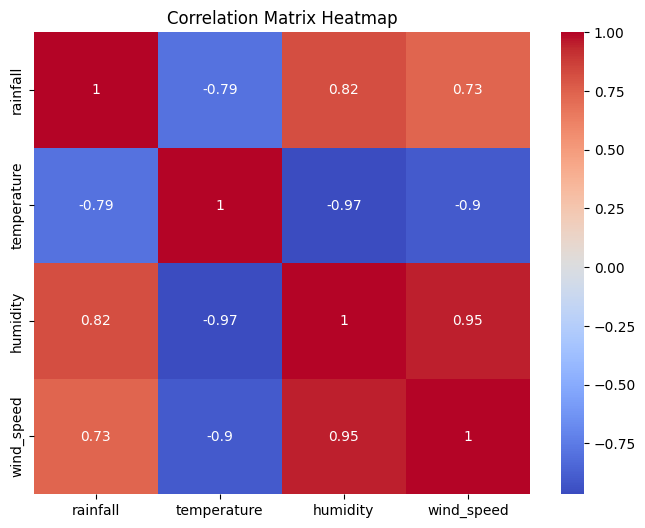

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix Heatmap")
plt.show()

### Correlation with the Target Variable

Rainfall is the main quantity of interest, so the correlations of all other features with rainfall are sorted from highest to lowest.

In [13]:
corr_matrix["rainfall"].sort_values(ascending=False)

,rainfall
rainfall,1.000000
humidity,0.821357
wind_speed,0.733376
temperature,-0.790566


### Detecting Multicollinearity

Feature pairs with correlation above 0.8 carry almost the same information, which can hurt some models. A double loop over the matrix finds them.

In [14]:
high_corr = []

for i in corr_matrix.columns:
    for j in corr_matrix.columns:
        if i != j and abs(corr_matrix[i][j]) > 0.8:
            high_corr.append((i, j, corr_matrix[i][j]))

high_corr

[('rainfall', 'humidity', np.float64(0.8213569723603099)),
 ('temperature', 'humidity', np.float64(-0.9660971268282758)),
 ('temperature', 'wind_speed', np.float64(-0.9029958088261343)),
 ('humidity', 'rainfall', np.float64(0.8213569723603099)),
 ('humidity', 'temperature', np.float64(-0.9660971268282758)),
 ('humidity', 'wind_speed', np.float64(0.9516425912012718)),
 ('wind_speed', 'temperature', np.float64(-0.9029958088261343)),
 ('wind_speed', 'humidity', np.float64(0.9516425912012718))]

Correlation observations:

- Humidity rises strongly with rainfall
- Temperature moves in the opposite direction to humidity and wind speed
- Several pairs cross the 0.8 threshold, so some features are redundant with others

## Distribution Analysis

Distributions describe how the values of a variable are spread out: the overall shape, whether it is skewed left or right, and where outliers sit.

### Histograms of All Numerical Features

A histogram with a kernel density estimate is drawn for every numeric column in one loop.

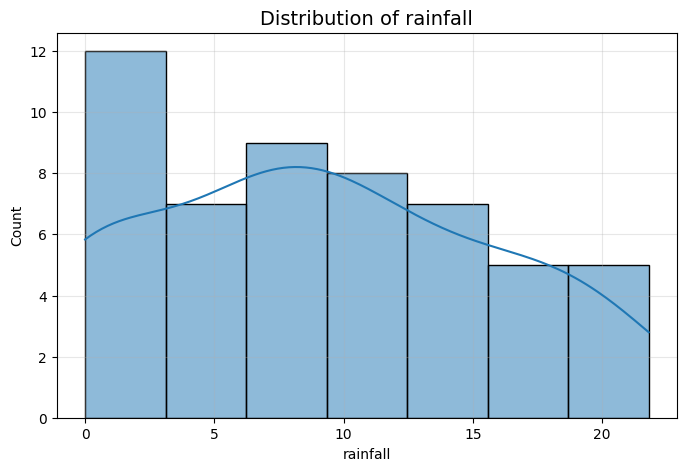

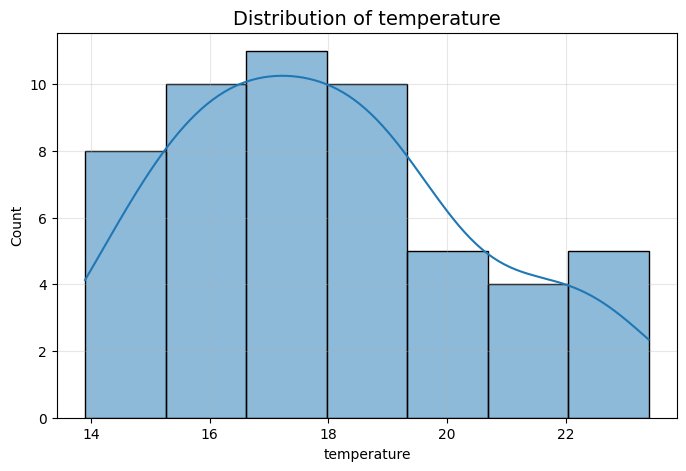

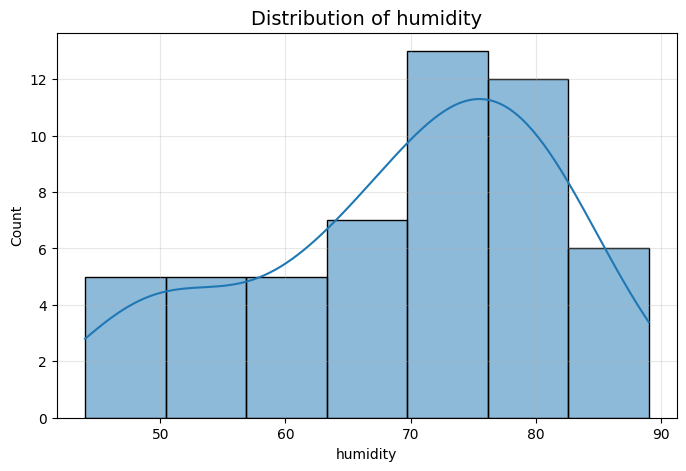

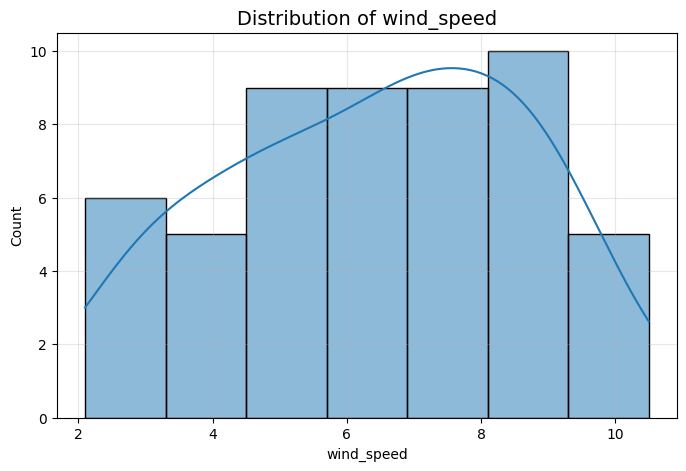

In [15]:
import numpy as np

numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    plt.figure(figsize=(8, 5))
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f"Distribution of {col}", fontsize=14)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.grid(True, alpha=0.3)
    plt.show()

Things to read off the histograms:

- Is the shape symmetric or skewed to one side
- Are the values concentrated around a peak or spread out

### Boxplots for Outlier Detection

The points lying outside the whiskers of a boxplot are potential outliers.

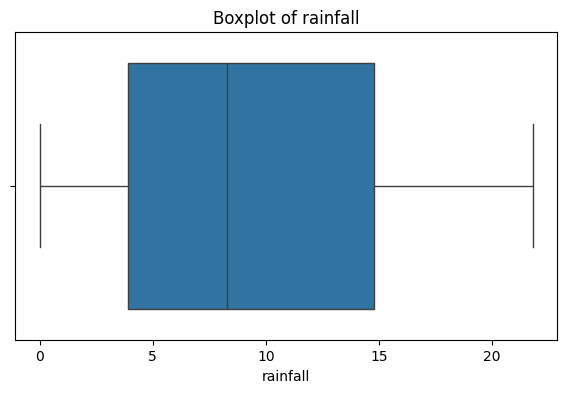

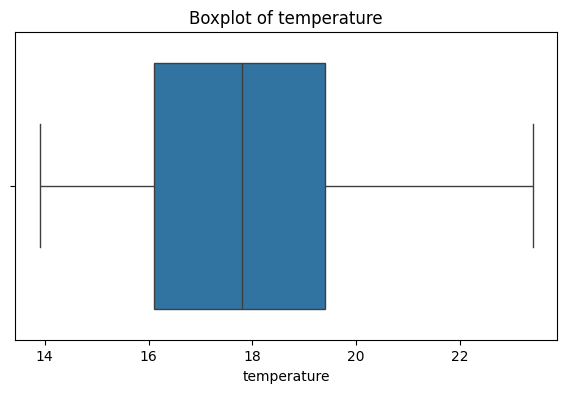

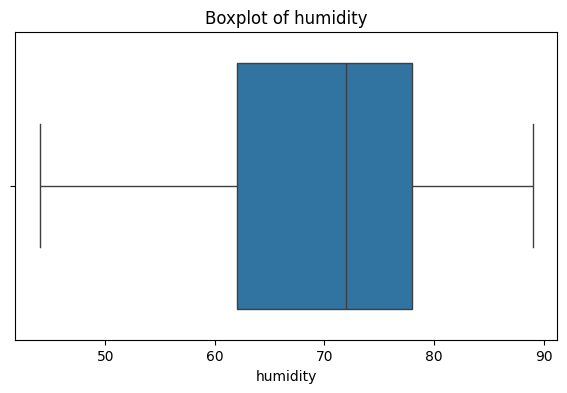

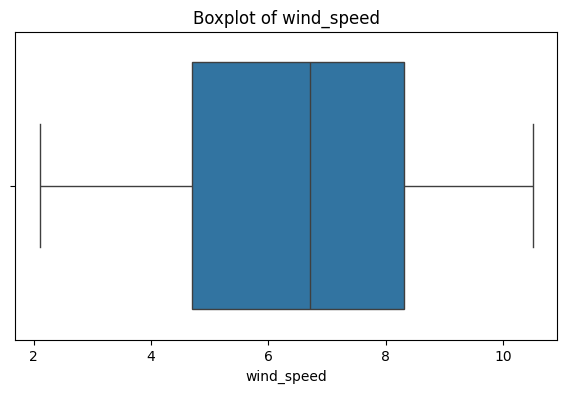

In [16]:
for col in df.select_dtypes(include='number').columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

### KDE Plots

A density curve shows the same shape as the histogram but smoothed, which makes skewness easier to see.

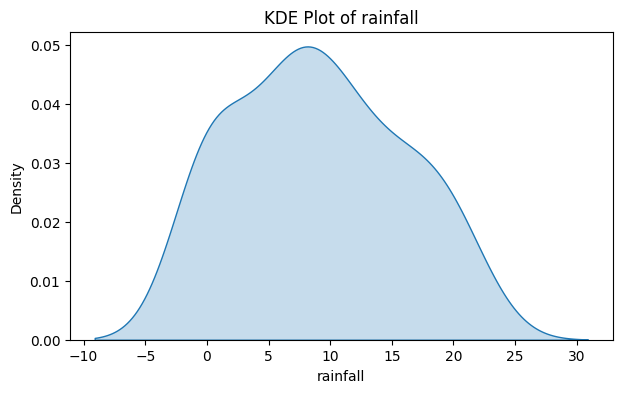

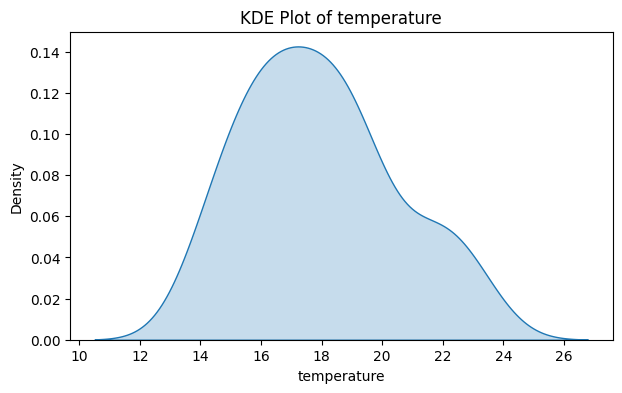

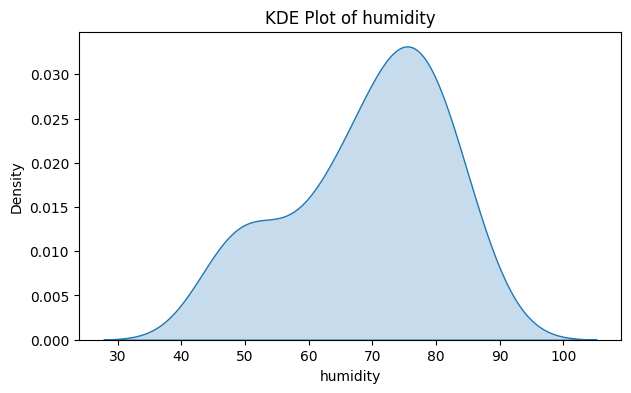

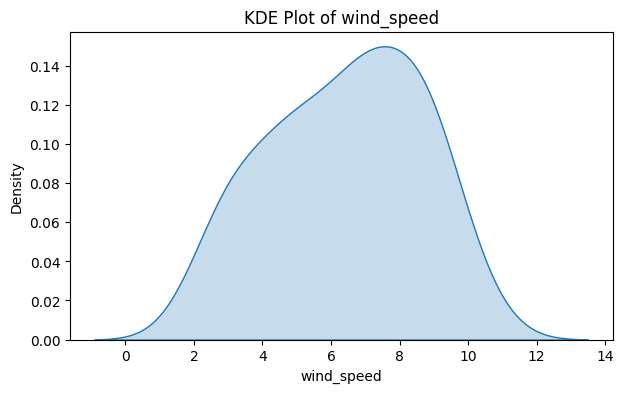

In [17]:
for col in df.select_dtypes(include='number').columns:
    plt.figure(figsize=(7, 4))
    sns.kdeplot(df[col], fill=True)
    plt.title(f"KDE Plot of {col}")
    plt.show()

### Skewness Values

Skew near 0 means a roughly normal shape, a positive value means a longer right tail and a negative value means a longer left tail.

In [18]:
df.skew(numeric_only=True)

,0
rainfall,0.191925
temperature,0.436075
humidity,-0.564768
wind_speed,-0.207329


Distribution observations:

- Which features are heavily skewed
- Which boxplots show points beyond the whiskers
- Which features look close to a normal distribution

## Insights Extraction

Insights are the conclusions drawn from all the analysis above: what the data shows, why it behaves that way, and which features matter most.

### Basic Aggregations of Rainfall

In [19]:
print("Average Rainfall:", df["rainfall"].mean())
print("Maximum Rainfall:", df["rainfall"].max())
print("Minimum Rainfall:", df["rainfall"].min())

Average Rainfall: 9.049056603773584
Maximum Rainfall: 21.8
Minimum Rainfall: 0.0


### Group-wise Analysis

Comparing average rainfall across the two weather conditions shows the label matches the measurement.

In [20]:
avg_rainfall = df.groupby("weather_condition")["rainfall"].mean()
print("Average Rainfall by Weather Condition:")
print(avg_rainfall)

Average Rainfall by Weather Condition:
weather_condition
Rainy    11.419048
Sunny     0.000000
Name: rainfall, dtype: float64


### Feature vs Target Scatterplots

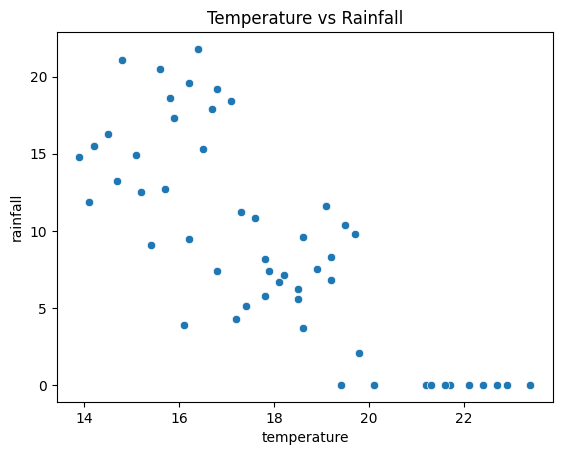

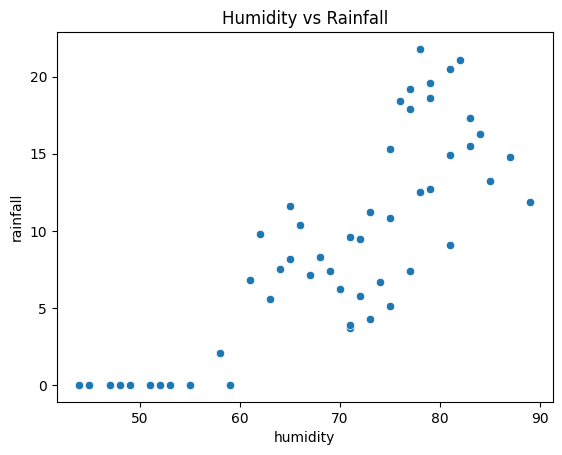

In [21]:
sns.scatterplot(x="temperature", y="rainfall", data=df)
plt.title("Temperature vs Rainfall")
plt.show()

sns.scatterplot(x="humidity", y="rainfall", data=df)
plt.title("Humidity vs Rainfall")
plt.show()

### Summary of Insights

- Humidity shows a strong positive correlation with rainfall
- Temperature has a negative correlation with both rainfall and humidity
- The weather condition label agrees completely with the rainfall values
- A few features are right skewed and some columns show outliers in their boxplots
- Humidity, temperature and wind speed are inter-correlated, so not all of them are needed as model inputs

## Practice Assignment

### Level 1: Basic

#### Q1. Display the first 10 rows of the dataset

In [22]:
df.head(10)

,date,rainfall,temperature,humidity,wind_speed,weather_condition
0,2022-01-01,12.5,15.2,78.0,8.5,Rainy
1,2022-01-02,8.2,17.8,65.0,5.2,Rainy
2,2022-01-03,0.0,20.1,52.0,3.1,Sunny
3,2022-01-04,3.7,18.6,71.0,6.7,Rainy
4,2022-01-05,21.1,14.8,82.0,9.3,Rainy
5,2022-01-06,15.3,16.5,75.0,7.8,Rainy
6,2022-01-07,6.8,19.2,61.0,4.5,Rainy
7,2022-01-08,0.0,21.7,48.0,2.9,Sunny
8,2022-01-09,11.2,17.3,73.0,6.1,Rainy
9,2022-01-10,18.6,15.8,79.0,8.9,Rainy


#### Q2. Number of rows and columns

In [23]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 54
Columns: 6


#### Q3. Print all column names

In [24]:
for col in df.columns:
    print(col)

date
rainfall
temperature
humidity
wind_speed
weather_condition


#### Q4. Data types of each column

In [25]:
df.dtypes

,0
date,object
rainfall,float64
temperature,float64
humidity,float64
wind_speed,float64
weather_condition,object


#### Q5. Total missing values in each column

In [26]:
df.isna().sum()

,0
date,0
rainfall,1
temperature,1
humidity,1
wind_speed,1
weather_condition,1


#### Q6. Mean, median and standard deviation of rainfall

In [27]:
print("Mean  :", df["rainfall"].mean())
print("Median:", df["rainfall"].median())
print("Std   :", df["rainfall"].std())

Mean  : 9.049056603773584
Median: 8.3
Std   : 6.712520524005565


#### Q7. Maximum and minimum temperature

In [28]:
print("Max temperature:", df["temperature"].max())
print("Min temperature:", df["temperature"].min())

Max temperature: 23.4
Min temperature: 13.9


#### Q8. Select only numerical columns

In [29]:
df.select_dtypes(include='number').head()

,rainfall,temperature,humidity,wind_speed
0,12.5,15.2,78.0,8.5
1,8.2,17.8,65.0,5.2
2,0.0,20.1,52.0,3.1
3,3.7,18.6,71.0,6.7
4,21.1,14.8,82.0,9.3


### Level 2: Correlation

#### Q9. Compute the correlation matrix

In [30]:
corr = df.corr(numeric_only=True)
corr

,rainfall,temperature,humidity,wind_speed
rainfall,1.000000,-0.790566,0.821357,0.733376
temperature,-0.790566,1.000000,-0.966097,-0.902996
humidity,0.821357,-0.966097,1.000000,0.951643
wind_speed,0.733376,-0.902996,0.951643,1.000000


#### Q10. Plot a heatmap of the correlation matrix

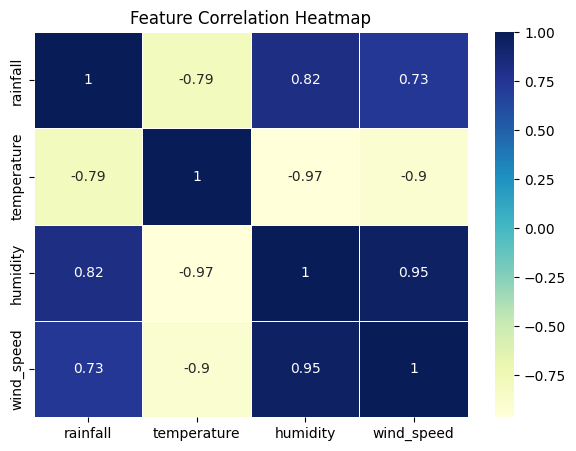

In [31]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="YlGnBu", linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

#### Q11. Correlation of all features with rainfall, sorted

In [32]:
rainfall_corr = corr["rainfall"].drop("rainfall").sort_values(ascending=False)
rainfall_corr

,rainfall
humidity,0.821357
wind_speed,0.733376
temperature,-0.790566


#### Q12. Identify feature pairs with correlation greater than 0.7

In [33]:
pairs = []

cols = corr.columns
for a in range(len(cols)):
    for b in range(a + 1, len(cols)):
        value = corr.iloc[a, b]
        if abs(value) > 0.7:
            pairs.append((cols[a], cols[b], round(value, 3)))

pairs

[('rainfall', 'temperature', np.float64(-0.791)),
 ('rainfall', 'humidity', np.float64(0.821)),
 ('rainfall', 'wind_speed', np.float64(0.733)),
 ('temperature', 'humidity', np.float64(-0.966)),
 ('temperature', 'wind_speed', np.float64(-0.903)),
 ('humidity', 'wind_speed', np.float64(0.952))]

#### Q13. Extract the highly correlated features into a list

In [34]:
highly_correlated = []
for first, second, value in pairs:
    if first not in highly_correlated:
        highly_correlated.append(first)
    if second not in highly_correlated:
        highly_correlated.append(second)

highly_correlated

['rainfall', 'temperature', 'humidity', 'wind_speed']

#### Q14. Drop one feature from each highly correlated pair

Wind speed is dropped since it is strongly tied to humidity, and the reduced matrix is checked again.

In [35]:
reduced_df = df.drop(columns=["wind_speed"])
reduced_corr = reduced_df.corr(numeric_only=True)
reduced_corr

,rainfall,temperature,humidity
rainfall,1.000000,-0.790566,0.821357
temperature,-0.790566,1.000000,-0.966097
humidity,0.821357,-0.966097,1.000000


#### Q15. Scatter plot between rainfall and humidity

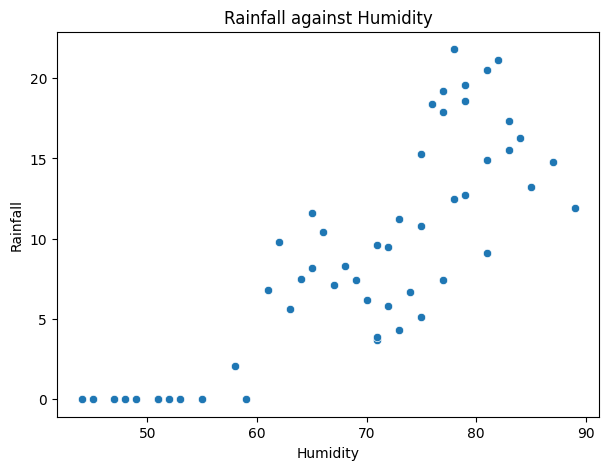

In [36]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x="humidity", y="rainfall", data=df)
plt.title("Rainfall against Humidity")
plt.xlabel("Humidity")
plt.ylabel("Rainfall")
plt.show()

### Level 3: Distribution

#### Q16. Histograms for all numerical features

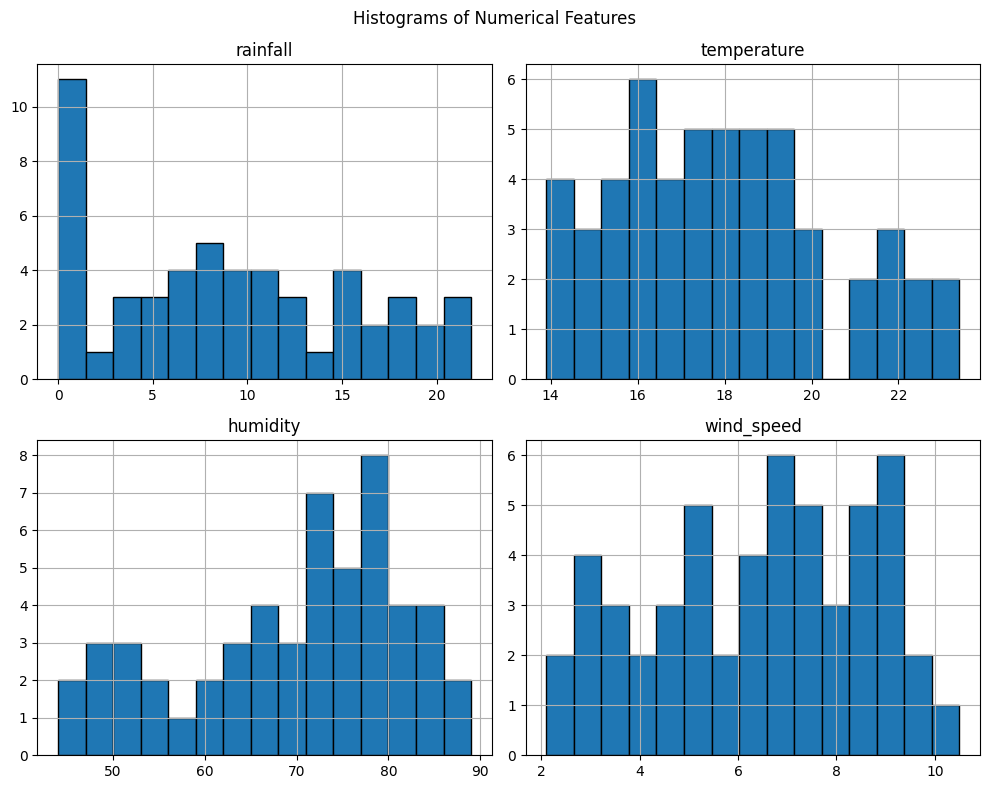

In [37]:
df.hist(figsize=(10, 8), bins=15, edgecolor="black")
plt.suptitle("Histograms of Numerical Features")
plt.tight_layout()
plt.show()

#### Q17. Histogram of rainfall with 30 bins

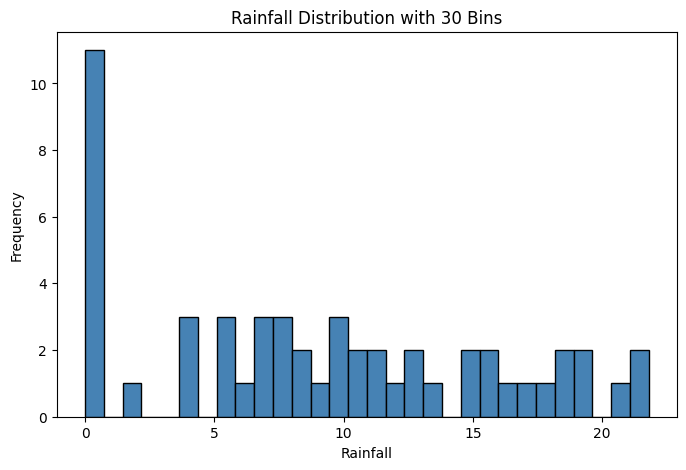

In [38]:
plt.figure(figsize=(8, 5))
plt.hist(df["rainfall"].dropna(), bins=30, color="steelblue", edgecolor="black")
plt.title("Rainfall Distribution with 30 Bins")
plt.xlabel("Rainfall")
plt.ylabel("Frequency")
plt.show()

#### Q18. Boxplots for all numerical columns

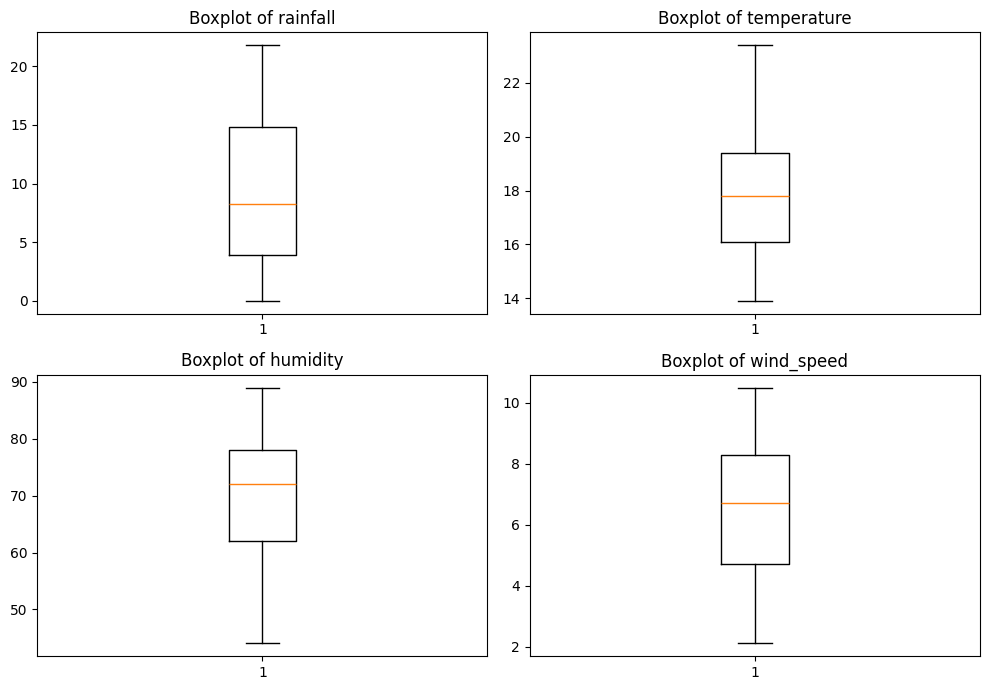

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, col in zip(axes.flat, df.select_dtypes(include='number').columns):
    ax.boxplot(df[col].dropna())
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

#### Q19. Identify outliers using the IQR method

In [40]:
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr_value = q3 - q1
    lower = q1 - 1.5 * iqr_value
    upper = q3 + 1.5 * iqr_value
    mask = (df[col] < lower) | (df[col] > upper)
    print(col, "outlier count:", mask.sum())

rainfall outlier count: 0
temperature outlier count: 0
humidity outlier count: 0
wind_speed outlier count: 0


#### Q20. Skewness for all numerical features

In [41]:
skew_values = df.select_dtypes(include='number').skew()
print(skew_values)

rainfall       0.191925
temperature    0.436075
humidity      -0.564768
wind_speed    -0.207329
dtype: float64


#### Q21. KDE plot for temperature

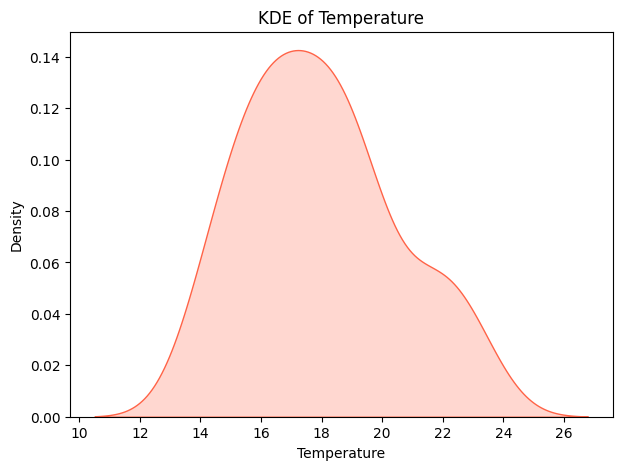

In [42]:
plt.figure(figsize=(7, 5))
sns.kdeplot(df["temperature"], fill=True, color="tomato")
plt.title("KDE of Temperature")
plt.xlabel("Temperature")
plt.show()

#### Q22. Compare the mean and median of rainfall

If the two values differ noticeably, the column is skewed in the direction of the larger one.

In [43]:
print("Mean  :", df["rainfall"].mean())
print("Median:", df["rainfall"].median())
print("Difference:", df["rainfall"].mean() - df["rainfall"].median())

Mean  : 9.049056603773584
Median: 8.3
Difference: 0.7490566037735835


#### Q23. Count how many features are right-skewed

In [44]:
right_skewed = skew_values[skew_values > 0.5]
print("Right-skewed features:", list(right_skewed.index))
print("Count:", len(right_skewed))

Right-skewed features: []
Count: 0


### Level 4: Insights

#### Q24. Average rainfall grouped by weather condition

In [45]:
df.groupby("weather_condition")["rainfall"].agg(["mean", "max", "min", "count"])

,mean,max,min,count
weather_condition,,,,
Rainy,11.419048,21.8,2.1,42
Sunny,0.000000,0.0,0.0,11


#### Q25. Top 3 records with highest rainfall

In [46]:
df.nlargest(3, "rainfall")

,date,rainfall,temperature,humidity,wind_speed,weather_condition
29,2022-01-30,21.8,16.4,78.0,7.6,Rainy
4,2022-01-05,21.1,14.8,82.0,9.3,Rainy
44,2022-02-14,20.5,15.6,81.0,8.2,Rainy


#### Q26. Rows where rainfall is greater than the average

In [47]:
above_average = df[df["rainfall"] > df["rainfall"].mean()]
print("Rows above average rainfall:", len(above_average))
above_average.head()

Rows above average rainfall: 26


,date,rainfall,temperature,humidity,wind_speed,weather_condition
0,2022-01-01,12.5,15.2,78.0,8.5,Rainy
4,2022-01-05,21.1,14.8,82.0,9.3,Rainy
5,2022-01-06,15.3,16.5,75.0,7.8,Rainy
8,2022-01-09,11.2,17.3,73.0,6.1,Rainy
9,2022-01-10,18.6,15.8,79.0,8.9,Rainy


#### Q27. Average temperature for high vs low rainfall days

Days whose rainfall is above the overall median are treated as high rainfall days.

In [48]:
median_rain = df["rainfall"].median()

high_days = df[df["rainfall"] > median_rain]["temperature"].mean()
low_days = df[df["rainfall"] <= median_rain]["temperature"].mean()

print("Average temperature on high rainfall days:", high_days)
print("Average temperature on low rainfall days :", low_days)

Average temperature on high rainfall days: 16.253846153846155
Average temperature on low rainfall days : 19.585185185185182


#### Q28. Create a high_rainfall column

In [49]:
import numpy as np

df["high_rainfall"] = np.where(df["rainfall"] > df["rainfall"].mean(), 1, 0)
df[["rainfall", "high_rainfall"]].head()

,rainfall,high_rainfall
0,12.5,1
1,8.2,0
2,0.0,0
3,3.7,0
4,21.1,1


#### Q29. Count the high rainfall records

In [50]:
df["high_rainfall"].value_counts()

,count
high_rainfall,
0,28
1,26


#### Q30. Correlation for high rainfall records only

In [51]:
df[df["high_rainfall"] == 1].corr(numeric_only=True).round(3)

,rainfall,temperature,humidity,wind_speed,high_rainfall
rainfall,1.000,-0.346,0.409,0.325,NaN
temperature,-0.346,1.000,-0.944,-0.917,NaN
humidity,0.409,-0.944,1.000,0.940,NaN
wind_speed,0.325,-0.917,0.940,1.000,NaN
high_rainfall,NaN,NaN,NaN,NaN,NaN


### Level 5: Advanced

#### Q31. Function to detect outliers using IQR

In [52]:
def find_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr_value = q3 - q1
    lower = q1 - 1.5 * iqr_value
    upper = q3 + 1.5 * iqr_value
    return series[(series < lower) | (series > upper)]

find_outliers(df["temperature"])

,temperature


#### Q32. Remove outliers from the rainfall column

In [53]:
q1, q3 = df["rainfall"].quantile([0.25, 0.75])
iqr_value = q3 - q1
lower, upper = q1 - 1.5 * iqr_value, q3 + 1.5 * iqr_value

before = len(df)
df_rain_clean = df[(df["rainfall"] >= lower) & (df["rainfall"] <= upper)]
print(f"Rows before: {before}, after removing rainfall outliers: {len(df_rain_clean)}")

Rows before: 54, after removing rainfall outliers: 53


#### Q33. Min-Max normalisation of numerical features

In [54]:
from sklearn.preprocessing import MinMaxScaler

minmax_df = pd.DataFrame(
    MinMaxScaler().fit_transform(df[numeric_cols]),
    columns=numeric_cols,
)
minmax_df.describe().round(3)

,rainfall,temperature,humidity,wind_speed
count,53.000,53.000,53.000,53.000
mean,0.415,0.426,0.561,0.512
std,0.308,0.263,0.266,0.263
min,0.000,0.000,0.000,0.000
25%,0.179,0.232,0.400,0.310
50%,0.381,0.411,0.622,0.548
75%,0.679,0.579,0.756,0.738
max,1.000,1.000,1.000,1.000


#### Q34. Standardisation using z-scores

In [55]:
from sklearn.preprocessing import StandardScaler

zscore_df = pd.DataFrame(
    StandardScaler().fit_transform(df[numeric_cols]),
    columns=numeric_cols,
)
zscore_df.describe().round(3)

,rainfall,temperature,humidity,wind_speed
count,53.000,53.000,53.000,53.000
mean,0.000,0.000,0.000,-0.000
std,1.010,1.010,1.010,1.010
min,-1.361,-1.635,-2.129,-1.967
25%,-0.774,-0.747,-0.611,-0.779
50%,-0.113,-0.061,0.232,0.135
75%,0.865,0.585,0.738,0.867
max,1.918,2.200,1.666,1.872


#### Q35. Pairplot of the important features

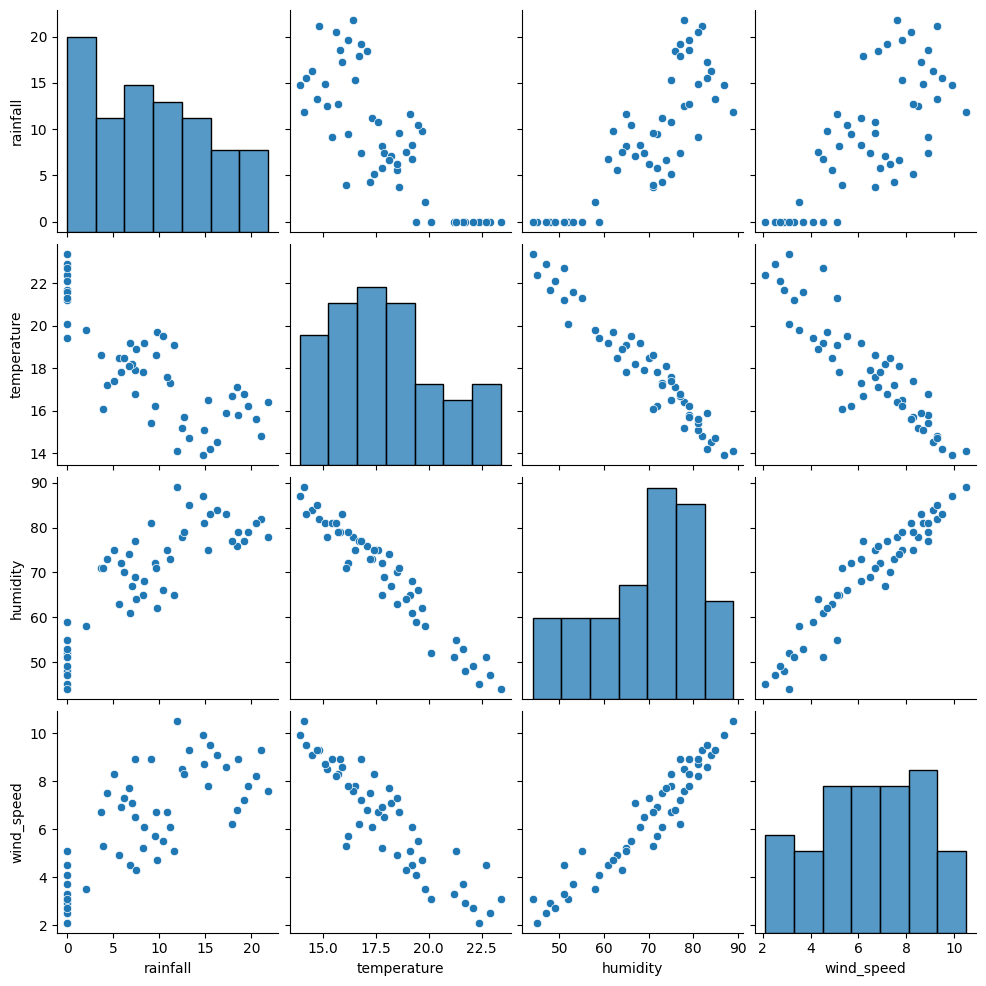

In [56]:
sns.pairplot(df[["rainfall", "temperature", "humidity", "wind_speed"]])
plt.show()

#### Q36. Automatic insight generation: features correlated with rainfall above 0.5

In [57]:
for feature, value in corr["rainfall"].drop("rainfall").items():
    if abs(value) > 0.5:
        print(f"{feature} is strongly related to rainfall (correlation = {value:.2f})")

temperature is strongly related to rainfall (correlation = -0.79)
humidity is strongly related to rainfall (correlation = 0.82)
wind_speed is strongly related to rainfall (correlation = 0.73)


#### Q37. Check whether the target is imbalanced

The target labels should appear in roughly equal numbers for a balanced classification dataset.

In [58]:
target_counts = df["weather_condition"].value_counts(normalize=True)
print(target_counts)
print("Imbalance ratio:", target_counts.max() / target_counts.min())

weather_condition
Rainy    0.792453
Sunny    0.207547
Name: proportion, dtype: float64
Imbalance ratio: 3.8181818181818183


#### Q38. Rainfall distribution before and after removing outliers

Two density curves are overlaid on one set of axes so the effect of the outlier removal is visible.

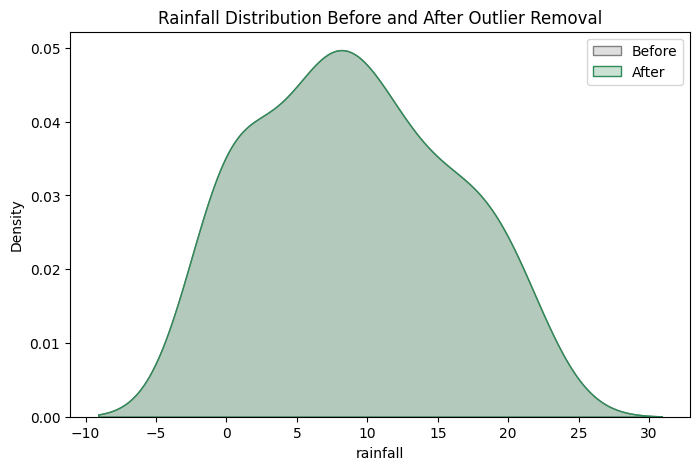

In [59]:
plt.figure(figsize=(8, 5))
sns.kdeplot(df["rainfall"], fill=True, label="Before", color="gray")
sns.kdeplot(df_rain_clean["rainfall"], fill=True, label="After", color="seagreen")
plt.title("Rainfall Distribution Before and After Outlier Removal")
plt.legend()
plt.show()

#### Q39. Summary report: mean, skewness and outlier count per column

In [60]:
summary = pd.DataFrame({
    "mean": df[numeric_cols].mean(),
    "skewness": df[numeric_cols].skew(),
    "outliers": [len(find_outliers(df[col])) for col in numeric_cols],
})
summary.round(3)

,mean,skewness,outliers
rainfall,9.049,0.192,0
temperature,17.951,0.436,0
humidity,69.245,-0.565,0
wind_speed,6.404,-0.207,0


#### Q40. Reusable function that performs a full basic EDA

The function combines the structure checks, correlation ranking and distribution snapshot into one call.

In [61]:
def quick_eda(data):
    print("Shape:", data.shape)
    print("\nMissing values:\n", data.isnull().sum())
    print("\nSummary statistics:\n", data.describe().round(2))
    corr = data.select_dtypes(include='number').corr()
    target_key = corr.columns[0]
    print(f"\nCorrelations with {target_key}:")
    corr[target_key].drop(target_key).sort_values(ascending=False)
    return corr

quick_eda(df)

Shape: (54, 7)

Missing values:
 date                 0
rainfall             1
temperature          1
humidity             1
wind_speed           1
weather_condition    1
high_rainfall        0
dtype: int64

Summary statistics:
        rainfall  temperature  humidity  wind_speed  high_rainfall
count     53.00        53.00     53.00       53.00          54.00
mean       9.05        17.95     69.25        6.40           0.48
std        6.71         2.50     11.97        2.21           0.50
min        0.00        13.90     44.00        2.10           0.00
25%        3.90        16.10     62.00        4.70           0.00
50%        8.30        17.80     72.00        6.70           0.00
75%       14.80        19.40     78.00        8.30           1.00
max       21.80        23.40     89.00       10.50           1.00

Correlations with rainfall:


,rainfall,temperature,humidity,wind_speed,high_rainfall
rainfall,1.000000,-0.790566,0.821357,0.733376,0.841399
temperature,-0.790566,1.000000,-0.966097,-0.902996,-0.672346
humidity,0.821357,-0.966097,1.000000,0.951643,0.692789
wind_speed,0.733376,-0.902996,0.951643,1.000000,0.605465
high_rainfall,0.841399,-0.672346,0.692789,0.605465,1.000000
